# Proyek Analisis Data: [Bike Sharing Dataset]
- **Nama:** Rai Tyas Febrika
- **Email:** ds014b6x1495@student.devacademy.id
- **ID Dicoding:** DS014b6x1495

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Musim apa yang menghasilkan rata-rata penyewaan sepeda harian tertinggi dan terendah pada Capital Bikeshare sepanjang tahun 2011–2012 untuk menentukan alokasi distribusi armada?
- **Pertanyaan 2:** Bagaimana selisih rata-rata penyewaan sepeda antara pengguna kasual dan terdaftar pada hari kerja selama tahun 2011–2012 guna menyusun strategi konversi keanggotaan?
- **Pertanyaan 3:** Kelompok jam operasional mana yang mencatat rata-rata volume penyewaan sepeda per jam tertinggi dan terendah selama tahun 2011–2012 sebagai acuan penjadwalan pemeliharaan armada?

## Import Semua Packages/Library yang Digunakan

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

## Data Wrangling

Tahap *Data Wrangling* dilakukan untuk menyiapkan dataset sebelum dianalisis lebih lanjut. Proses ini mencakup tiga langkah utama, yaitu pengumpulan data (*Gathering Data*), penilaian kualitas data (*Assessing Data*), serta pembersihan dan perbaikan anomali data (*Cleaning Data*).

### Gathering Data

Pada tahap ini, dilakukan proses pemuatan (*loading*) dataset Bike Sharing yang terdiri dari dua file utama, yaitu `day.csv` (data agregasi penyewaan harian) dan `hour.csv` (data agregasi penyewaan per jam). Langkah ini bertujuan memastikan seluruh data terbaca dengan baik ke dalam DataFrame serta menampilkan sampel baris awal untuk mengenali struktur dan variabel yang tersedia.

#### Load df day_df




In [2]:
day_df = pd.read_csv("data/day.csv")
print("ukuran day_df:",day_df.shape)
display(day_df.head())


ukuran day_df: (731, 16)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


**Insight:** (Opsional)
- DataFrame day_df merepresentasikan total catatan penyewaan sepeda secara harian
- memiliki 731 baris data dan 16 kolom

#### Load df hour_df

In [3]:
hour_df = pd.read_csv("data/hour.csv")
print("ukuran hour_df:",hour_df.shape)
display(hour_df.head())

ukuran hour_df: (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:** (Opsional)
- DataFrame hour_df merekam rincian jumlah penyewaan sepeda pada setiap jam, sehingga memungkinkan analisis pola penyewaan berdasarkan jam operasional harian. 
- DataFrame ini memiliki 17379 baris data dan 17 kolom

### Assessing Data

Tahap ini bertujuan mengevaluasi kualitas, konsistensi, dan integritas data pada `day_df` maupun `hour_df`. Pemeriksaan dilakukan secara menyeluruh terhadap kesesuaian tipe data, keberadaan nilai yang hilang (*missing value*), data duplikat, invalid value, inaccurate value, serta deteksi *outlier* menggunakan metode *Interquartile Range* (IQR).

#### Identifying day_df problem

##### 1. Memeriksa tipe data

In [4]:
day_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


##### 2. Memeriksa missing value

In [5]:
day_df.isna().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

##### 3. Memeriksa duplicate data

In [6]:
print("Jumlah duplikasi: ", day_df.duplicated().sum()) 

Jumlah duplikasi:  0


##### 4. Memeriksa parameter statistik

In [7]:
day_df.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


##### 5. Memeriksa invalid value (memastikan kode kategori dan nilai numerik tidak keluar dari rentang aturan dokumentasi)

In [8]:
day_df[
    (~day_df["season"].isin([1, 2, 3, 4])) |
    (~day_df["yr"].isin([0, 1])) |
    (~day_df["mnth"].between(1, 12)) |
    (~day_df["holiday"].isin([0, 1])) |
    (~day_df["weekday"].between(0, 6)) |
    (~day_df["workingday"].isin([0, 1])) |
    (~day_df["weathersit"].isin([1, 2, 3, 4])) |
    (day_df["casual"] < 0) |
    (day_df["registered"] < 0) |
    (day_df["cnt"] < 0)
]

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt


##### 6. Memeriksa inaccurate value (kelembapan hum == 0 atau kecepatan angin windspeed == 0 yang tidak realistis secara meteorologis)

In [9]:
day_df[(day_df["hum"] == 0) | (day_df["windspeed"] == 0)]

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
68,69,2011-03-10,1,0,3,0,4,1,3,0.389091,0.385668,0.0,0.261877,46,577,623


##### 7. Memeriksa inconsistent value (ketidaksesuaian penjumlahan casual + registered != cnt atau ketidakcocokan tahun/bulan dengan dteday)

In [10]:
day_dt = pd.to_datetime(day_df["dteday"])
day_df[
    (day_df["casual"] + day_df["registered"] != day_df["cnt"]) |
    ((day_dt.dt.year - 2011) != day_df["yr"]) |
    (day_dt.dt.month != day_df["mnth"])
]

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt


##### 8. Memeriksa outlier menggunakan metode IQR

In [11]:
num_cols_day = ["temp", "atemp", "hum", "windspeed", "casual", "registered", "cnt"]
Q1 = day_df[num_cols_day].quantile(0.25)
Q3 = day_df[num_cols_day].quantile(0.75)
IQR = Q3 - Q1
maximum = Q3 + (1.5 * IQR)
minimum = Q1 - (1.5 * IQR)

((day_df[num_cols_day] < minimum) | (day_df[num_cols_day] > maximum)).sum()

temp           0
atemp          0
hum            2
windspeed     13
casual        44
registered     0
cnt            0
dtype: int64

In [12]:
#Menampilkan detail baris outlier pada kolom hum (2 baris)
day_df[(day_df["hum"] < minimum["hum"]) | (day_df["hum"] > maximum["hum"])]

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
49,50,2011-02-19,1,0,2,0,6,0,1,0.399167,0.391404,0.187917,0.507463,532,1103,1635
68,69,2011-03-10,1,0,3,0,4,1,3,0.389091,0.385668,0.000000,0.261877,46,577,623


In [13]:
#Menampilkan detail baris outlier pada kolom windspeed (13 baris)
day_df[(day_df["windspeed"] < minimum["windspeed"]) | (day_df["windspeed"] > maximum["windspeed"])]

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
44,45,2011-02-14,1,0,2,0,1,1,1,0.415000,0.398350,0.375833,0.417908,208,1705,1913
49,50,2011-02-19,1,0,2,0,6,0,1,0.399167,0.391404,0.187917,0.507463,532,1103,1635
93,94,2011-04-04,2,0,4,0,1,1,1,0.573333,0.542929,0.426250,0.385571,734,2381,3115
94,95,2011-04-05,2,0,4,0,2,1,2,0.414167,0.398350,0.642083,0.388067,167,1628,1795
292,293,2011-10-20,4,0,10,0,4,1,1,0.475833,0.466525,0.636250,0.422275,471,3724,4195
382,383,2012-01-18,1,1,1,0,3,1,1,0.303333,0.275254,0.443333,0.415429,109,3267,3376
407,408,2012-02-12,1,1,2,0,0,0,1,0.127500,0.101658,0.464583,0.409212,73,1456,1529
420,421,2012-02-25,1,1,2,0,6,0,1,0.290833,0.255675,0.395833,0.421642,317,2415,2732
432,433,2012-03-08,1,1,3,0,4,1,1,0.527500,0.524604,0.567500,0.441563,486,4896,5382
433,434,2012-03-09,1,1,3,0,5,1,2,0.410833,0.397083,0.407083,0.414800,447,4122,4569


In [14]:
#Menampilkan detail baris outlier pada kolom casual (44 baris)
day_df[(day_df["casual"] < minimum["casual"]) | (day_df["casual"] > maximum["casual"])]

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
148,149,2011-05-29,2,0,5,0,0,0,1,0.667500,0.615550,0.818750,0.213938,2355,2433,4788
183,184,2011-07-03,3,0,7,0,0,0,2,0.716667,0.668575,0.682500,0.228858,2282,2367,4649
184,185,2011-07-04,3,0,7,1,1,0,2,0.726667,0.665417,0.637917,0.081479,3065,2978,6043
196,197,2011-07-16,3,0,7,0,6,0,1,0.686667,0.638263,0.585000,0.208342,2418,3505,5923
246,247,2011-09-04,3,0,9,0,0,0,1,0.709167,0.665429,0.742083,0.206467,2521,2419,4940
281,282,2011-10-09,4,0,10,0,0,0,1,0.540833,0.523983,0.727500,0.063450,2397,3114,5511
441,442,2012-03-17,1,1,3,0,6,0,2,0.514167,0.505046,0.755833,0.110704,3155,4681,7836
447,448,2012-03-23,2,1,3,0,5,1,2,0.601667,0.570067,0.694167,0.116300,2469,5893,8362
455,456,2012-03-31,2,1,3,0,6,0,2,0.424167,0.421708,0.738333,0.250617,2301,3934,6235
456,457,2012-04-01,2,1,4,0,0,0,2,0.425833,0.417287,0.676250,0.172267,2347,3694,6041


**Steps to Take:**
- **Mengubah Tipe Data:** Mengonversi tipe data kolom `dteday` dari `object` menjadi `datetime64` agar dapat digunakan untuk analisis deret waktu (*time-series*).
- **Memperbaiki *Inaccurate Value* & *Outlier* pada `hum`:**
  - Mengganti nilai kelembapan `hum == 0.0` pada index ke-68 (`instant = 69`, tanggal `2011-03-10`) menggunakan nilai rata-rata (`mean`) kolom `hum` pada tanggal `2011-03-10` dari `hour_df` yang telah dibersihkan (`0.965000`). **Alasannya:** karena `day_df` merupakan tabel agregasi harian dari `hour_df`, mengambil nilai rata-rata langsung dari hasil interpolasi per jam menjaga konsistensi data antar-tabel (*single source of truth*) dan lebih akurat secara meteorologis dibandingkan interpolasi terpisah antar-hari.
  - Mempertahankan 1 baris *outlier* `hum` lainnya (index ke-49, tanggal `2011-02-19`, `hum = 0.187917`) karena terjadi pada cuaca cerah (`weathersit = 1`) dengan angin kencang (`windspeed = 0.507463`), yang merupakan kondisi udara kering alami di akhir musim dingin.
- **Mempertahankan *Outlier* Alami pada `windspeed` dan `casual`:** Tidak menghapus maupun mengubah 13 baris *outlier* pada `windspeed` dan 44 baris *outlier* pada `casual`, karena nilai tersebut mencerminkan variasi cuaca berangin yang wajar serta lonjakan penyewaan alami oleh pengguna rekreasi pada akhir pekan/hari libur yang cerah.
- **Konversi Label Kategorikal:** Memetakan kode angka pada kolom kategorik (`season`, `yr`, `mnth`, `holiday`, `weekday`, `workingday`, dan `weathersit`) menjadi label teks deskriptif agar lebih mudah dibaca saat eksplorasi dan visualisasi.
- **Denormalisasi Fitur Lingkungan:** Mengonversi kolom cuaca yang masih ternormalisasi (`temp`, `atemp`, `hum`, dan `windspeed`) ke dalam satuan aslinya (`Celsius`, `persen`, dan `km/jam`).

**Insight:** (Opsional)
- **Kualitas Kelengkapan & Konsistensi Data:** Dari total 731 baris pada `day_df`, tidak ditemukan adanya *missing value* (`0`), duplikasi data (`0`), *invalid value* (`0`), maupun *inconsistent value* (`0` pada penjumlahan `casual + registered == cnt` serta kesesuaian tahun dan bulan dengan `dteday`).
- **Temuan *Inaccurate Value* pada Kelembapan:** Ditemukan 1 baris bermasalah pada tanggal `2011-03-10` (index ke-68) dengan nilai `hum = 0.0`, padahal pada hari tersebut tercatat cuaca hujan/salju ringan (`weathersit = 3`), sehingga dapat dipastikan terjadi kegagalan pencatatan sensor cuaca.
- **Karakteristik *Outlier* pada Data Harian:** Melalui metode IQR, ditemukan *outlier* pada 3 kolom yaitu `hum` (2 baris), `windspeed` (13 baris), dan `casual` (44 baris). Setelah diinspeksi, 1 *outlier* pada `hum` (`0.0`) merupakan *error* pencatatan, sedangkan 1 *outlier* `hum` lainnya (`0.187917`) serta seluruh *outlier* pada `windspeed` dan `casual` merupakan fenomena cuaca dan lonjakan permintaan akhir pekan yang valid di lapangan.
- **Distribusi Kondisi Cuaca Harian:** Nilai maksimum `weathersit` pada `day_df` hanya mencapai skala **3** (*Light Snow/Rain*) dan tidak pernah mencapai skala **4** (*Heavy Rain/Ice Pallets*) seperti pada dokumentasi, yang menunjukkan bahwa cuaca ekstrem hanya terjadi dalam durasi singkat (hitungan jam) sehingga teredam saat diagregasi menjadi data harian.
- **Format Kolom yang Belum Siap Eksplorasi:** Kolom `dteday` masih tersimpan sebagai teks (`object`), 7 kolom kategorikal masih berbentuk kode numerik, dan 4 fitur lingkungan masih berada dalam skala normalisasi.

#### Identifying hour_df problem

##### 1. Memeriksa tipe data

In [15]:
hour_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


##### 2. Memeriksa missing value

In [16]:
hour_df.isna().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

##### 3. Memeriksa duplicate data

In [17]:
print("Jumlah duplikasi: ", hour_df.duplicated().sum()) 

Jumlah duplikasi:  0


##### 4. Memeriksa parameter statistik

In [18]:
hour_df.describe()

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


##### 5. Memeriksa invalid value (memastikan kode kategori dan nilai numerik tidak keluar dari rentang aturan dokumentasi)

In [19]:
hour_df[
    (~hour_df["season"].isin([1, 2, 3, 4])) |
    (~hour_df["yr"].isin([0, 1])) |
    (~hour_df["mnth"].between(1, 12)) |
    (~hour_df["hr"].between(0, 23)) |
    (~hour_df["holiday"].isin([0, 1])) |
    (~hour_df["weekday"].between(0, 6)) |
    (~hour_df["workingday"].isin([0, 1])) |
    (~hour_df["weathersit"].isin([1, 2, 3, 4])) |
    (hour_df["casual"] < 0) |
    (hour_df["registered"] < 0) |
    (hour_df["cnt"] < 0)
]

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt


##### 6. Memeriksa inaccurate value (kelembapan hum == 0 atau kecepatan angin windspeed == 0)

In [20]:
hour_df[hour_df["hum"] == 0] #kelembapan

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
1551,1552,2011-03-10,1,0,3,0,0,4,1,3,0.34,0.3182,0.0,0.2537,3,0,3
1552,1553,2011-03-10,1,0,3,1,0,4,1,3,0.34,0.3182,0.0,0.2537,0,2,2
1553,1554,2011-03-10,1,0,3,2,0,4,1,3,0.34,0.3182,0.0,0.2537,0,1,1
1554,1555,2011-03-10,1,0,3,5,0,4,1,3,0.36,0.3485,0.0,0.1940,1,2,3
1555,1556,2011-03-10,1,0,3,6,0,4,1,3,0.36,0.3333,0.0,0.3284,0,12,12
1556,1557,2011-03-10,1,0,3,7,0,4,1,3,0.38,0.3939,0.0,0.2239,1,36,37
1557,1558,2011-03-10,1,0,3,8,0,4,1,3,0.38,0.3939,0.0,0.2836,1,43,44
1558,1559,2011-03-10,1,0,3,9,0,4,1,3,0.40,0.4091,0.0,0.2239,1,23,24
1559,1560,2011-03-10,1,0,3,10,0,4,1,3,0.40,0.4091,0.0,0.1642,0,17,17
1560,1561,2011-03-10,1,0,3,11,0,4,1,3,0.40,0.4091,0.0,0.2537,6,5,11


In [21]:
hour_df[hour_df["windspeed"] == 0]

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17319,17320,2012-12-29,1,1,12,12,0,6,0,3,0.20,0.2424,1.00,0.0,5,43,48
17320,17321,2012-12-29,1,1,12,13,0,6,0,3,0.20,0.2424,1.00,0.0,13,71,84
17322,17323,2012-12-29,1,1,12,15,0,6,0,2,0.24,0.2424,0.87,0.0,19,110,129
17330,17331,2012-12-29,1,1,12,23,0,6,0,2,0.26,0.2424,0.60,0.0,0,32,32


##### 7. Memeriksa inconsistent value (ketidaksesuaian casual + registered != cnt serta kecocokan tahun dan bulan dengan dteday)

In [22]:
hour_dt = pd.to_datetime(hour_df["dteday"])
hour_df[
    (hour_df["casual"] + hour_df["registered"] != hour_df["cnt"]) |
    ((hour_dt.dt.year - 2011) != hour_df["yr"]) |
    (hour_dt.dt.month != hour_df["mnth"])
]

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt


##### 8. Memeriksa jumlah outlier menggunakan metode IQR

In [23]:
num_cols_hour = ["temp", "atemp", "hum", "windspeed", "casual", "registered", "cnt"]
Q1_hr = hour_df[num_cols_hour].quantile(0.25)
Q3_hr = hour_df[num_cols_hour].quantile(0.75)
IQR_hr = Q3_hr - Q1_hr
maximum_hr = Q3_hr + (1.5 * IQR_hr)
minimum_hr = Q1_hr - (1.5 * IQR_hr)

((hour_df[num_cols_hour] < minimum_hr) | (hour_df[num_cols_hour] > maximum_hr)).sum()

temp             0
atemp            0
hum             22
windspeed      342
casual        1192
registered     680
cnt            505
dtype: int64

In [24]:
#Menampilkan detail baris outlier pada kolom hum (22 baris)
hour_df[(hour_df["hum"] < minimum_hr["hum"]) | (hour_df["hum"] > maximum_hr["hum"])]

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
1551,1552,2011-03-10,1,0,3,0,0,4,1,3,0.34,0.3182,0.0,0.2537,3,0,3
1552,1553,2011-03-10,1,0,3,1,0,4,1,3,0.34,0.3182,0.0,0.2537,0,2,2
1553,1554,2011-03-10,1,0,3,2,0,4,1,3,0.34,0.3182,0.0,0.2537,0,1,1
1554,1555,2011-03-10,1,0,3,5,0,4,1,3,0.36,0.3485,0.0,0.1940,1,2,3
1555,1556,2011-03-10,1,0,3,6,0,4,1,3,0.36,0.3333,0.0,0.3284,0,12,12
1556,1557,2011-03-10,1,0,3,7,0,4,1,3,0.38,0.3939,0.0,0.2239,1,36,37
1557,1558,2011-03-10,1,0,3,8,0,4,1,3,0.38,0.3939,0.0,0.2836,1,43,44
1558,1559,2011-03-10,1,0,3,9,0,4,1,3,0.40,0.4091,0.0,0.2239,1,23,24
1559,1560,2011-03-10,1,0,3,10,0,4,1,3,0.40,0.4091,0.0,0.1642,0,17,17
1560,1561,2011-03-10,1,0,3,11,0,4,1,3,0.40,0.4091,0.0,0.2537,6,5,11


In [25]:
#Menampilkan detail baris outlier pada kolom windspeed (342 baris)
hour_df[(hour_df["windspeed"] < minimum_hr["windspeed"]) | (hour_df["windspeed"] > maximum_hr["windspeed"])]

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
175,176,2011-01-08,1,0,1,14,0,6,0,1,0.20,0.1667,0.32,0.4925,12,83,95
178,179,2011-01-08,1,0,1,17,0,6,0,1,0.16,0.1212,0.37,0.5522,5,64,69
194,195,2011-01-09,1,0,1,9,0,0,0,1,0.12,0.0758,0.46,0.5224,0,19,19
196,197,2011-01-09,1,0,1,11,0,0,0,1,0.16,0.1212,0.40,0.5224,2,47,49
265,266,2011-01-12,1,0,1,12,0,3,1,1,0.20,0.1515,0.47,0.5821,3,52,55
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17327,17328,2012-12-29,1,1,12,20,0,6,0,2,0.30,0.2424,0.56,0.5522,2,64,66
17328,17329,2012-12-29,1,1,12,21,0,6,0,2,0.28,0.2424,0.56,0.4925,4,56,60
17341,17342,2012-12-30,1,1,12,10,0,0,0,1,0.26,0.2121,0.41,0.5821,31,91,122
17343,17344,2012-12-30,1,1,12,12,0,0,0,1,0.28,0.2273,0.36,0.5821,47,97,144


In [26]:
#Menampilkan detail baris outlier pada kolom casual (1.192 baris)
hour_df[(hour_df["casual"] < minimum_hr["casual"]) | (hour_df["casual"] > maximum_hr["casual"])]

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
1633,1634,2011-03-13,1,0,3,14,0,0,0,1,0.46,0.4545,0.41,0.2985,144,106,250
1634,1635,2011-03-13,1,0,3,15,0,0,0,1,0.48,0.4697,0.39,0.3284,149,155,304
1635,1636,2011-03-13,1,0,3,16,0,0,0,1,0.46,0.4545,0.41,0.3881,124,132,256
1771,1772,2011-03-19,1,0,3,12,0,6,0,1,0.46,0.4545,0.33,0.4179,126,141,267
1772,1773,2011-03-19,1,0,3,13,0,6,0,1,0.50,0.4848,0.34,0.4627,174,127,301
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16817,16818,2012-12-08,4,1,12,12,0,6,0,2,0.40,0.4091,0.87,0.2239,122,364,486
16818,16819,2012-12-08,4,1,12,13,0,6,0,2,0.40,0.4091,0.87,0.1642,148,399,547
16819,16820,2012-12-08,4,1,12,14,0,6,0,2,0.40,0.4091,0.87,0.2836,164,378,542
16820,16821,2012-12-08,4,1,12,15,0,6,0,1,0.42,0.4242,0.82,0.1642,167,374,541


In [27]:
#Menampilkan detail baris outlier pada kolom registered (680 baris)
hour_df[(hour_df["registered"] < minimum_hr["registered"]) | (hour_df["registered"] > maximum_hr["registered"])]

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
2995,2996,2011-05-09,2,0,5,17,0,1,1,1,0.62,0.6212,0.38,0.2537,59,539,598
3019,3020,2011-05-10,2,0,5,17,0,2,1,1,0.64,0.6212,0.33,0.0000,79,532,611
3067,3068,2011-05-12,2,0,5,17,0,4,1,2,0.64,0.6212,0.57,0.1940,54,540,594
3187,3188,2011-05-17,2,0,5,17,0,2,1,1,0.62,0.6061,0.65,0.4179,83,521,604
3379,3380,2011-05-25,2,0,5,17,0,3,1,1,0.74,0.6667,0.51,0.2239,77,524,601
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17063,17064,2012-12-18,4,1,12,18,0,2,1,1,0.38,0.3939,0.46,0.3284,13,512,525
17077,17078,2012-12-19,4,1,12,8,0,3,1,1,0.24,0.2576,0.87,0.1045,13,665,678
17086,17087,2012-12-19,4,1,12,17,0,3,1,1,0.40,0.4091,0.50,0.3881,26,536,562
17087,17088,2012-12-19,4,1,12,18,0,3,1,1,0.38,0.3939,0.50,0.3582,23,546,569


In [28]:
#Menampilkan detail baris outlier pada kolom cnt (505 baris)
hour_df[(hour_df["cnt"] < minimum_hr["cnt"]) | (hour_df["cnt"] > maximum_hr["cnt"])]

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
5536,5537,2011-08-23,3,0,8,14,0,2,1,1,0.72,0.6515,0.30,0.0896,149,502,651
10358,10359,2012-03-12,1,1,3,17,0,1,1,2,0.62,0.6212,0.38,0.4179,87,557,644
10359,10360,2012-03-12,1,1,3,18,0,1,1,2,0.60,0.6212,0.43,0.1940,89,623,712
10382,10383,2012-03-13,1,1,3,17,0,2,1,1,0.70,0.6364,0.37,0.1045,62,614,676
10383,10384,2012-03-13,1,1,3,18,0,2,1,1,0.70,0.6364,0.34,0.2985,96,638,734
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16885,16886,2012-12-11,4,1,12,8,0,2,1,2,0.34,0.3030,0.61,0.2985,16,708,724
16909,16910,2012-12-12,4,1,12,8,0,3,1,2,0.26,0.2576,0.65,0.1642,18,670,688
16933,16934,2012-12-13,4,1,12,8,0,4,1,1,0.24,0.2273,0.60,0.1940,24,655,679
17053,17054,2012-12-18,4,1,12,8,0,2,1,1,0.38,0.3939,0.94,0.0000,10,652,662


**Steps to Take:**
- **Mengubah Tipe Data:** Mengonversi tipe data kolom `dteday` pada `hour_df` dari `object` menjadi `datetime64` agar selaras dengan `day_df` dan mendukung analisis deret waktu (*time-series*).
- **Memperbaiki *Inaccurate Value* pada `hum` (22 baris):**
  - Mengganti 22 baris dengan nilai `hum == 0.0` (seluruhnya terjadi pada tanggal `2011-03-10`) menjadi `NaN`, lalu melakukan imputasi menggunakan metode interpolasi linear sebelum membersihkan `day_df`. **Alasannya:** nilai `0.0` dianggap angka sah oleh Python sehingga harus diubah menjadi `NaN`, dan interpolasi linear dipilih untuk menjaga kesinambungan pola kelembapan antar-jam sekaligus menjadi acuan agregasi yang konsisten bagi tanggal `2011-03-10` pada `day_df`.
- **Mempertahankan Nilai `windspeed == 0.0` (2.180 baris):**
  - Tidak mengubah maupun melakukan interpolasi pada 2.180 baris yang memiliki `windspeed == 0.0`. **Alasannya:** kecepatan angin di bawah ambang batas sensitivitas alat ukur meteorologi (*anemometer threshold*, di bawah ~6 km/jam) secara standar tercatat sebagai `0.0` (*calm wind*), selain itu variabel kecepatan angin tidak menjadi fokus utama dalam pertanyaan bisnis yang dianalisis.
- **Mempertahankan *Outlier* Alami pada `windspeed`, `casual`, `registered`, dan `cnt`:**
  - Tidak menghapus maupun mengubah 342 baris *outlier* pada `windspeed`, 1.192 baris pada `casual`, 680 baris pada `registered`, serta 505 baris pada `cnt` (sedangkan 22 *outlier* pada `hum` otomatis tertangani melalui imputasi nilai `0.0`). **Alasannya:** lonjakan volume penyewaan di atas batas IQR mencerminkan perilaku nyata pengguna di lapangan (lonjakan komuter pada *rush hour* hari kerja dan pengguna rekreasi pada akhir pekan), sedangkan kecepatan angin tinggi merupakan variasi cuaca yang sah.
- **Konversi Label Kategorikal:** Memetakan kode angka pada kolom kategorik (`season`, `yr`, `mnth`, `holiday`, `weekday`, `workingday`, dan `weathersit`) menjadi label teks deskriptif yang konsisten dengan `day_df`.
- **Denormalisasi Fitur Lingkungan:** Mengonversi kolom cuaca yang masih ternormalisasi (`temp`, `atemp`, `hum`, dan `windspeed`) ke dalam satuan aslinya (`Celsius`, `persen`, dan `km/jam`).

**Insight:** (Opsional)
- **Kelengkapan & Konsistensi Data:** Dari 17.379 baris pada `hour_df`, tidak ditemukan adanya *missing value* (`0`), duplikasi data (`0`), *invalid value* (`0` pada seluruh rentang kategori maupun jam `0–23`), maupun *inconsistent value* (`0` pada penjumlahan `casual + registered == cnt` serta pemetaan tahun dan bulan dengan `dteday`).
- **Temuan pada Kelembapan dan Kecepatan Angin:** Ditemukan **22 baris** dengan kelembapan tidak akurat (`hum = 0.0` pada tanggal `2011-03-10`) yang menjadi sumber nilai `hum = 0.0` pada agregasi harian `day_df` di tanggal yang sama. Selain itu, ditemukan **2.180 baris** (~12,5% data) dengan `windspeed = 0.0` yang merepresentasikan kondisi angin tenang di bawah ambang ukur anemometer (`< 6 km/jam`).
- **Karakteristik *Outlier* pada Data Per Jam:** Berdasarkan metode IQR, terdeteksi *outlier* pada kolom `hum` (22 baris), `windspeed` (342 baris), `casual` (1.192 baris), `registered` (680 baris), dan `cnt` (505 baris). Tingginya jumlah *outlier* pada kolom penyewaan disebabkan oleh distribusi penyewaan per jam yang miring ke kanan (*right-skewed*), di mana penyewaan sangat rendah pada dini hari dan melonjak tajam pada jam sibuk komuter.
- **Kemunculan Cuaca Ekstrem pada Resolusi Jam:** Berbeda dengan `day_df` yang maksimal `weathersit`-nya bernilai `3`, pada `hour_df` nilai maksimum `weathersit` mencapai **4** (*Heavy Rain/Ice Pallets*), membuktikan bahwa cuaca ekstrem hanya terjadi dalam durasi jam tertentu saja.
- **Statistik Penyewaan & Struktur Kolom:** Rata-rata penyewaan sepeda tercatat sekitar **189 sepeda/jam** dengan rentang **1** hingga **977 sepeda/jam**, sementara kolom `dteday` masih bertipe `object` dan fitur lingkungan masih dalam bentuk ternormalisasi sehingga perlu dibersihkan sebelum masuk ke tahap EDA.

### Cleaning Data

Berdasarkan temuan pada tahap *Assessing Data*, proses pembersihan difokuskan pada perbaikan tipe data kolom tanggal (`dteday`) menjadi format `datetime64` serta penanganan nilai kelembapan (`hum`) bernilai `0.0` pada tanggal 10 Maret 2011 menggunakan interpolasi linear pada `hour_df` yang kemudian disinkronkan ke `day_df`. Sementara itu, *outlier* alami dan nilai kecepatan angin (`windspeed`) nol tetap dipertahankan karena merepresentasikan kondisi operasional dan cuaca yang valid, melakukan konversi kode numerik pada kolom kategorik menjadi label teks deskriptif, serta melakukan denormalisasi nilai cuaca dan lingkungan ke satuan asli

#### Fixing hour_df problem

##### Langkah 1: Mengubah tipe data kolom `dteday` menjadi `datetime`

In [29]:
hour_df["dteday"] = pd.to_datetime(hour_df["dteday"])

#periksa kembali
hour_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     17379 non-null  int64         
 1   dteday      17379 non-null  datetime64[ns]
 2   season      17379 non-null  int64         
 3   yr          17379 non-null  int64         
 4   mnth        17379 non-null  int64         
 5   hr          17379 non-null  int64         
 6   holiday     17379 non-null  int64         
 7   weekday     17379 non-null  int64         
 8   workingday  17379 non-null  int64         
 9   weathersit  17379 non-null  int64         
 10  temp        17379 non-null  float64       
 11  atemp       17379 non-null  float64       
 12  hum         17379 non-null  float64       
 13  windspeed   17379 non-null  float64       
 14  casual      17379 non-null  int64         
 15  registered  17379 non-null  int64         
 16  cnt         17379 non-

##### Langkah 2: Memperbaiki *inaccurate value* pada kolom `hum` (`hum == 0`) menggunakan interpolasi linear

In [30]:
hour_df["hum"] = hour_df["hum"].replace(0, np.nan).interpolate(method="linear")
hour_df[hour_df["dteday"] == "2011-03-10"][["instant", "dteday", "hr", "weathersit", "hum"]]

,instant,dteday,hr,weathersit,hum
1551,1552,2011-03-10,0,3,0.933043
1552,1553,2011-03-10,1,3,0.936087
1553,1554,2011-03-10,2,3,0.939130
1554,1555,2011-03-10,5,3,0.942174
1555,1556,2011-03-10,6,3,0.945217
1556,1557,2011-03-10,7,3,0.948261
1557,1558,2011-03-10,8,3,0.951304
1558,1559,2011-03-10,9,3,0.954348
1559,1560,2011-03-10,10,3,0.957391
1560,1561,2011-03-10,11,3,0.960435


##### Langkah 3: Mengonversi kode numerik pada kolom kategorik menjadi label teks deskriptif

In [31]:
season_map = {1: "Spring", 2: "Summer", 3: "Fall", 4: "Winter"}
yr_map = {0: 2011, 1: 2012}
mnth_map = {
    1: "Jan",
    2: "Feb",
    3: "Mar",
    4: "Apr",
    5: "May",
    6: "Jun",
    7: "Jul",
    8: "Aug",
    9: "Sep",
    10: "Oct",
    11: "Nov",
    12: "Dec"
}
holiday_map = {0: "Non-Holiday", 1: "Holiday"}
weekday_map = {
    0: "Sunday",
    1: "Monday",
    2: "Tuesday",
    3: "Wednesday",
    4: "Thursday",
    5: "Friday",
    6: "Saturday"
}
workingday_map = {0: "Holiday/Weekend", 1: "Working Day"}
weathersit_map = {
    1: "Clear/Partly Cloudy",
    2: "Mist/Cloudy",
    3: "Light Snow/Rain",
    4: "Heavy Rain/Snow"
}

hour_df["season"] = hour_df["season"].map(season_map)
hour_df["yr"] = hour_df["yr"].map(yr_map)
hour_df["mnth"] = hour_df["mnth"].map(mnth_map)
hour_df["holiday"] = hour_df["holiday"].map(holiday_map)
hour_df["weekday"] = hour_df["weekday"].map(weekday_map)
hour_df["workingday"] = hour_df["workingday"].map(workingday_map)
hour_df["weathersit"] = hour_df["weathersit"].map(weathersit_map)

hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,Spring,2011,Jan,0,Non-Holiday,Saturday,Holiday/Weekend,Clear/Partly Cloudy,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,Spring,2011,Jan,1,Non-Holiday,Saturday,Holiday/Weekend,Clear/Partly Cloudy,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,Spring,2011,Jan,2,Non-Holiday,Saturday,Holiday/Weekend,Clear/Partly Cloudy,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,Spring,2011,Jan,3,Non-Holiday,Saturday,Holiday/Weekend,Clear/Partly Cloudy,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,Spring,2011,Jan,4,Non-Holiday,Saturday,Holiday/Weekend,Clear/Partly Cloudy,0.24,0.2879,0.75,0.0,0,1,1


##### Langkah 4: Melakukan denormalisasi nilai cuaca dan lingkungan ke satuan asli

In [32]:
hour_df["temp_celsius"] = hour_df["temp"] * 41
hour_df["atemp_celsius"] = hour_df["atemp"] * 50
hour_df["hum_percent"] = hour_df["hum"] * 100
hour_df["windspeed_kmh"] = hour_df["windspeed"] * 67

hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,...,atemp,hum,windspeed,casual,registered,cnt,temp_celsius,atemp_celsius,hum_percent,windspeed_kmh
0,1,2011-01-01,Spring,2011,Jan,0,Non-Holiday,Saturday,Holiday/Weekend,Clear/Partly Cloudy,...,0.2879,0.81,0.0,3,13,16,9.84,14.395,81.0,0.0
1,2,2011-01-01,Spring,2011,Jan,1,Non-Holiday,Saturday,Holiday/Weekend,Clear/Partly Cloudy,...,0.2727,0.80,0.0,8,32,40,9.02,13.635,80.0,0.0
2,3,2011-01-01,Spring,2011,Jan,2,Non-Holiday,Saturday,Holiday/Weekend,Clear/Partly Cloudy,...,0.2727,0.80,0.0,5,27,32,9.02,13.635,80.0,0.0
3,4,2011-01-01,Spring,2011,Jan,3,Non-Holiday,Saturday,Holiday/Weekend,Clear/Partly Cloudy,...,0.2879,0.75,0.0,3,10,13,9.84,14.395,75.0,0.0
4,5,2011-01-01,Spring,2011,Jan,4,Non-Holiday,Saturday,Holiday/Weekend,Clear/Partly Cloudy,...,0.2879,0.75,0.0,0,1,1,9.84,14.395,75.0,0.0


**Insight:** (Opsional)
- Kolom `dteday` pada `hour_df` kini telah tersimpan dalam format waktu standar (`datetime64[ns]`), dan dimensi tabel bertambah dari **17 menjadi 21 kolom** setelah penambahan empat fitur cuaca berskala asli.
- Seluruh 22 baris dengan kelembapan tidak akurat (`hum == 0.0`) pada tanggal `2011-03-10` telah berhasil diimputasi menggunakan interpolasi linear menjadi rentang nilai **0,933 hingga 0,997** (93,3%–99,7%), yang jauh lebih realistis untuk kondisi cuaca hujan/salju ringan (`Light Snow/Rain`) dan menyisakan **0 nilai kosong (`NaN`)**.
- Seluruh atribut kategorikal kini terbaca dalam label teks deskriptif yang informatif, sementara nilai cuaca terdenormalisasi (`temp_celsius`, `atemp_celsius`, `hum_percent`, dan `windspeed_kmh`) siap digunakan untuk eksplorasi mendalam tanpa mengubah nilai `windspeed == 0.0` yang merepresentasikan kondisi angin tenang di bawah ambang alat ukur.

#### Fixing day_df problem

##### Langkah 1: Mengubah tipe data kolom `dteday` menjadi `datetime`

In [33]:
day_df["dteday"] = pd.to_datetime(day_df["dteday"])
day_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     731 non-null    int64         
 1   dteday      731 non-null    datetime64[ns]
 2   season      731 non-null    int64         
 3   yr          731 non-null    int64         
 4   mnth        731 non-null    int64         
 5   holiday     731 non-null    int64         
 6   weekday     731 non-null    int64         
 7   workingday  731 non-null    int64         
 8   weathersit  731 non-null    int64         
 9   temp        731 non-null    float64       
 10  atemp       731 non-null    float64       
 11  hum         731 non-null    float64       
 12  windspeed   731 non-null    float64       
 13  casual      731 non-null    int64         
 14  registered  731 non-null    int64         
 15  cnt         731 non-null    int64         
dtypes: datetime64[ns](1), floa

##### Langkah 2: Memperbaiki *inaccurate value* `hum == 0` menggunakan agregasi rata-rata `hour_df`

In [34]:
day_df.loc[day_df["dteday"] == "2011-03-10", "hum"] = hour_df[
    hour_df["dteday"] == "2011-03-10"
]["hum"].mean()

day_df[day_df["dteday"] == "2011-03-10"][["instant", "dteday", "weathersit", "temp", "hum", "windspeed", "cnt"]]

,instant,dteday,weathersit,temp,hum,windspeed,cnt
68,69,2011-03-10,3,0.389091,0.965,0.261877,623


##### Langkah 3: Mengonversi kode numerik pada kolom kategorik menjadi label teks deskriptif

In [35]:
day_df["season"] = day_df["season"].map(season_map)
day_df["yr"] = day_df["yr"].map(yr_map)
day_df["mnth"] = day_df["mnth"].map(mnth_map)
day_df["holiday"] = day_df["holiday"].map(holiday_map)
day_df["weekday"] = day_df["weekday"].map(weekday_map)
day_df["workingday"] = day_df["workingday"].map(workingday_map)
day_df["weathersit"] = day_df["weathersit"].map(weathersit_map)

day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,Spring,2011,Jan,Non-Holiday,Saturday,Holiday/Weekend,Mist/Cloudy,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,Spring,2011,Jan,Non-Holiday,Sunday,Holiday/Weekend,Mist/Cloudy,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,Spring,2011,Jan,Non-Holiday,Monday,Working Day,Clear/Partly Cloudy,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,Spring,2011,Jan,Non-Holiday,Tuesday,Working Day,Clear/Partly Cloudy,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,Spring,2011,Jan,Non-Holiday,Wednesday,Working Day,Clear/Partly Cloudy,0.226957,0.229270,0.436957,0.186900,82,1518,1600


##### Langkah 4: Melakukan denormalisasi nilai cuaca dan lingkungan ke satuan asli agar mudah terbaca

In [36]:
day_df["temp_celsius"] = day_df["temp"] * 41
day_df["atemp_celsius"] = day_df["atemp"] * 50
day_df["hum_percent"] = day_df["hum"] * 100
day_df["windspeed_kmh"] = day_df["windspeed"] * 67

day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,temp_celsius,atemp_celsius,hum_percent,windspeed_kmh
0,1,2011-01-01,Spring,2011,Jan,Non-Holiday,Saturday,Holiday/Weekend,Mist/Cloudy,0.344167,0.363625,0.805833,0.160446,331,654,985,14.110847,18.18125,80.5833,10.749882
1,2,2011-01-02,Spring,2011,Jan,Non-Holiday,Sunday,Holiday/Weekend,Mist/Cloudy,0.363478,0.353739,0.696087,0.248539,131,670,801,14.902598,17.68695,69.6087,16.652113
2,3,2011-01-03,Spring,2011,Jan,Non-Holiday,Monday,Working Day,Clear/Partly Cloudy,0.196364,0.189405,0.437273,0.248309,120,1229,1349,8.050924,9.47025,43.7273,16.636703
3,4,2011-01-04,Spring,2011,Jan,Non-Holiday,Tuesday,Working Day,Clear/Partly Cloudy,0.200000,0.212122,0.590435,0.160296,108,1454,1562,8.200000,10.60610,59.0435,10.739832
4,5,2011-01-05,Spring,2011,Jan,Non-Holiday,Wednesday,Working Day,Clear/Partly Cloudy,0.226957,0.229270,0.436957,0.186900,82,1518,1600,9.305237,11.46350,43.6957,12.522300


**Insight:** (Opsional)
- Kolom `dteday` pada `day_df` kini bertipe `datetime64[ns]`, dan dimensi tabel bertambah dari **16 menjadi 20 kolom** dengan format dan penamaan kategori yang 100% seragam dengan `hour_df`.
- Nilai kelembapan tidak valid (`hum == 0.0`) pada tanggal `2011-03-10` telah berhasil diperbaiki menjadi **`0.965`** (**96,50%**) berdasarkan rata-rata aktual seluruh jam pada hari yang sama di `hour_df`, sehingga menjaga konsistensi penuh antar-kedua dataset tanpa mengubah *outlier* cuaca kering alami (`18,79%` pada `2011-02-19`) maupun lonjakan penyewaan akhir pekan.


## Exploratory Data Analysis (EDA)

Pada tahap eksplorasi data, dilakukan analisis deskriptif dan agregasi lintas variabel pada `day_df` serta `hour_df` untuk menggali pola dan hubungan antarvariabel. Eksplorasi difokuskan pada tren pertumbuhan tahunan, pengaruh musim dan kondisi cuaca, perbedaan perilaku penyewaan antara pengguna *casual* dan *registered* pada hari kerja maupun hari libur, serta distribusi penyewaan berdasarkan jam operasional guna menjawab seluruh pertanyaan bisnis.

### Explore day_df

In [37]:
# Rangkuman parameter statistik seluruh kolom day_df
day_df.describe(include="all")

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,temp_celsius,atemp_celsius,hum_percent,windspeed_kmh
count,731.000000,731,731,731.000000,731,731,731,731,731,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
unique,NaN,NaN,4,NaN,12,2,7,2,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,Fall,NaN,Jan,Non-Holiday,Saturday,Working Day,Clear/Partly Cloudy,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,188,NaN,62,710,105,500,463,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,366.000000,2012-01-01 00:00:00,NaN,2011.500684,NaN,NaN,NaN,NaN,NaN,0.495385,0.474354,0.629214,0.190486,848.176471,3656.172367,4504.348837,20.310776,23.717699,62.921417,12.762576
min,1.000000,2011-01-01 00:00:00,NaN,2011.000000,NaN,NaN,NaN,NaN,NaN,0.059130,0.079070,0.187917,0.022392,2.000000,20.000000,22.000000,2.424346,3.953480,18.791700,1.500244
25%,183.500000,2011-07-02 12:00:00,NaN,2011.000000,NaN,NaN,NaN,NaN,NaN,0.337083,0.337842,0.521041,0.134950,315.500000,2497.000000,3152.000000,13.820424,16.892125,52.104150,9.041650
50%,366.000000,2012-01-01 00:00:00,NaN,2012.000000,NaN,NaN,NaN,NaN,NaN,0.498333,0.486733,0.627500,0.180975,713.000000,3662.000000,4548.000000,20.431653,24.336650,62.750000,12.125325
75%,548.500000,2012-07-01 12:00:00,NaN,2012.000000,NaN,NaN,NaN,NaN,NaN,0.655417,0.608602,0.730833,0.233214,1096.000000,4776.500000,5956.000000,26.872076,30.430100,73.083350,15.625371
max,731.000000,2012-12-31 00:00:00,NaN,2012.000000,NaN,NaN,NaN,NaN,NaN,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000,35.328347,42.044800,97.250000,34.000021


**Insight:**
- Dataset `day_df` mencakup **731 hari** pengamatan penuh selama tahun 2011–2012 dengan rata-rata penyewaan harian sebesar **4.504,35 sepeda/hari** (rentang **22** hingga **8.714 sepeda/hari**).
- Pengguna terdaftar (*registered*) memiliki rata-rata harian jauh lebih tinggi (**3.656,17 sepeda/hari**) dibandingkan pengguna kasual (*casual*) yang rata-ratanya **848,18 sepeda/hari**.

In [38]:
# Agregasi jumlah dan rata-rata penyewaan harian berdasarkan musim (Pertanyaan 1)
day_df.groupby(by="season").agg({
    "instant": "count",
    "cnt": ["mean", "median", "min", "max", "sum"],
    "temp_celsius": "mean"
}).sort_values(by=("cnt", "mean"), ascending=False)

instant          cnt                              temp_celsius
         count         mean  median   min   max      sum         mean
season                                                               
Fall       188  5644.303191  5353.5  1115  8714  1061129    28.958682
Summer     184  4992.331522  4941.5   795  8362   918589    22.320611
Winter     178  4728.162921  4634.5    22  8555   841613    17.339148
Spring     181  2604.132597  2209.0   431  7836   471348    12.207650

**Insight:**
- Musim Gugur (**Fall**) mencatat rata-rata penyewaan harian tertinggi sebesar **5.644,30 sepeda/hari** (total **1.061.129** penyewaan) sejalan dengan suhu rata-rata paling nyaman (**28,96 °C**).
- Musim Semi (**Spring**) mencatat rata-rata penyewaan terendah yaitu **2.604,13 sepeda/hari** (total **471.348** penyewaan) dengan suhu rata-rata terdingin (**12,21 °C**).

In [39]:
# Perbandingan tren rata-rata dan total penyewaan per musim antara tahun 2011 dan 2012 (Pertanyaan 1)
day_df.pivot_table(
    index="season",
    columns="yr",
    values="cnt",
    aggfunc=["mean", "sum"]
).reindex(["Fall", "Summer", "Winter", "Spring"])

mean                  sum        
yr             2011         2012    2011    2012
season                                          
Fall    4464.361702  6824.244681  419650  641479
Summer  3775.173913  6209.489130  347316  571273
Winter  3664.460674  5791.865169  326137  515476
Spring  1666.666667  3531.296703  150000  321348

**Insight:**
- Urutan peringkat volume penyewaan antar-musim (`Fall > Summer > Winter > Spring`) terbukti konsisten pada tahun **2011** maupun **2012**.
- Seluruh musim mengalami pertumbuhan penyewaan yang signifikan pada tahun 2012 dibandingkan tahun 2011 (misalnya pada musim *Fall* meningkat dari **4.464,36** menjadi **6.824,24 sepeda/hari**).

In [40]:
# Agregasi perbandingan penyewaan pengguna casual vs registered berdasarkan status hari kerja (Pertanyaan 2)
day_df.groupby(by="workingday").agg({
    "instant": "count",
    "casual": ["mean", "sum"],
    "registered": ["mean", "sum"],
    "cnt": ["mean", "sum"]
})

instant       casual           registered           \
                  count         mean     sum         mean      sum   
workingday                                                           
Holiday/Weekend     231  1371.134199  316732  2959.034632   683537   
Working Day         500   606.570000  303285  3978.250000  1989125   

                         cnt           
                        mean      sum  
workingday                             
Holiday/Weekend  4330.168831  1000269  
Working Day      4584.820000  2292410

**Insight:**
- Pada hari kerja (*Working Day*), rata-rata penyewaan pengguna terdaftar mencapai **3.978,25 sepeda/hari**, sedangkan pengguna kasual hanya **606,57 sepeda/hari** (selisih **3.371,68 sepeda/hari**).
- Pada akhir pekan/hari libur (*Holiday/Weekend*), rata-rata penyewaan pengguna kasual melonjak lebih dari dua kali lipat menjadi **1.371,13 sepeda/hari**, sementara pengguna terdaftar turun ke **2.959,03 sepeda/hari** (selisih menyempit menjadi **1.587,90 sepeda/hari**).

In [41]:
# Rata-rata penyewaan pengguna casual vs registered berdasarkan hari dalam seminggu (Pertanyaan 2)
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
day_df.groupby(by="weekday").agg({
    "casual": "mean",
    "registered": "mean",
    "cnt": "mean"
}).reindex(weekday_order)

,casual,registered,cnt
weekday,,,
Monday,674.133333,3663.990476,4338.123810
Tuesday,556.182692,3954.480769,4510.663462
Wednesday,551.144231,3997.394231,4548.538462
Thursday,590.961538,4076.298077,4667.259615
Friday,752.288462,3938.000000,4690.288462
Saturday,1465.257143,3085.285714,4550.542857
Sunday,1338.295238,2890.533333,4228.828571


**Insight:**
- Penyewaan oleh pengguna terdaftar stabil tinggi pada hari Senin hingga Jumat dengan puncak pada hari **Kamis** (**4.076,30 sepeda/hari**), mencerminkan penggunaan rutin untuk aktivitas komuter.
- Penyewaan oleh pengguna kasual mulai meningkat pada hari **Jumat** (**752,29 sepeda/hari**) dan mencapai puncaknya pada hari **Sabtu** (**1.465,26 sepeda/hari**) serta **Minggu** (**1.338,30 sepeda/hari**).

**Insight:** (Opsional)
- **Pola Penyewaan Berdasarkan Musim (Pertanyaan 1):** Musim Gugur (**Fall**) mencatat rata-rata penyewaan harian tertinggi sebesar **5.644,30 sepeda/hari** (total **1.061.129** penyewaan) sejalan dengan suhu rata-rata yang paling nyaman (**28,96 °C**). Sebaliknya, Musim Semi (**Spring**) mencatat rata-rata penyewaan terendah yaitu **2.604,13 sepeda/hari** (total **471.348** penyewaan) dengan suhu rata-rata terdingin (**12,21 °C**). Peringkat musim (`Fall > Summer > Winter > Spring`) konsisten terjadi pada tahun 2011 maupun 2012, dengan peningkatan volume yang signifikan di seluruh musim pada tahun 2012.
- **Perilaku Pengguna Kasual vs Terdaftar (Pertanyaan 2):** Pada hari kerja (*Working Day*), pengguna terdaftar mendominasi dengan rata-rata **3.978,25 sepeda/hari**, sedangkan pengguna kasual hanya **606,57 sepeda/hari** (terdapat selisih **3.371,68 sepeda/hari**). Sebaliknya, pada akhir pekan atau hari libur (*Holiday/Weekend*), rata-rata penyewaan pengguna kasual melonjak lebih dari dua kali lipat menjadi **1.371,13 sepeda/hari** (memuncak pada hari Sabtu sebesar **1.465,26 sepeda/hari**), sementara pengguna terdaftar turun ke **2.959,03 sepeda/hari** (selisih menyempit menjadi **1.587,90 sepeda/hari**).

### Explore hour_df

In [42]:
# Rangkuman parameter statistik seluruh kolom hour_df
hour_df.describe(include="all")

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,...,atemp,hum,windspeed,casual,registered,cnt,temp_celsius,atemp_celsius,hum_percent,windspeed_kmh
count,17379.0000,17379,17379,17379.000000,17379,17379.000000,17379,17379,17379,17379,...,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
unique,NaN,NaN,4,NaN,12,NaN,2,7,2,4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,Fall,NaN,Jul,NaN,Non-Holiday,Saturday,Working Day,Clear/Partly Cloudy,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,4496,NaN,1488,NaN,16879,2512,11865,11413,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,8690.0000,2012-01-02 04:08:34.552045568,NaN,2011.502561,NaN,11.546752,NaN,NaN,NaN,NaN,...,0.475775,0.628450,0.190098,35.676218,153.786869,189.463088,20.376474,23.788755,62.845043,12.736540
min,1.0000,2011-01-01 00:00:00,NaN,2011.000000,NaN,0.000000,NaN,NaN,NaN,NaN,...,0.000000,0.080000,0.000000,0.000000,0.000000,1.000000,0.820000,0.000000,8.000000,0.000000
25%,4345.5000,2011-07-04 00:00:00,NaN,2011.000000,NaN,6.000000,NaN,NaN,NaN,NaN,...,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000,13.940000,16.665000,48.000000,7.001500
50%,8690.0000,2012-01-02 00:00:00,NaN,2012.000000,NaN,12.000000,NaN,NaN,NaN,NaN,...,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000,20.500000,24.240000,63.000000,12.998000
75%,13034.5000,2012-07-02 00:00:00,NaN,2012.000000,NaN,18.000000,NaN,NaN,NaN,NaN,...,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000,27.060000,31.060000,78.000000,16.997900
max,17379.0000,2012-12-31 00:00:00,NaN,2012.000000,NaN,23.000000,NaN,NaN,NaN,NaN,...,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000,41.000000,50.000000,100.000000,56.996900


**Insight:**
- Dataset `hour_df` terdiri dari **17.379 catatan** per jam dengan rata-rata penyewaan sebesar **189,46 sepeda/jam** (rentang **1** hingga **977 sepeda/jam**).
- Distribusi penyewaan per jam cenderung miring ke kanan (*right-skewed*), di mana nilai median (**142 sepeda/jam**) lebih rendah dibandingkan nilai rata-ratanya (**189,46 sepeda/jam**).

In [43]:
# Agregasi rata-rata dan total volume penyewaan sepeda per jam (Pertanyaan 3)
hour_df.groupby(by="hr").agg({
    "instant": "count",
    "casual": "mean",
    "registered": "mean",
    "cnt": ["mean", "min", "max", "sum"]
})

instant     casual  registered         cnt                 
     count       mean        mean        mean min  max     sum
hr                                                            
0      726  10.158402   43.739669   53.898072   2  283   39130
1      724   6.504144   26.871547   33.375691   1  168   24164
2      715   4.772028   18.097902   22.869930   1  132   16352
3      697   2.715925    9.011478   11.727403   1   79    8174
4      697   1.253945    5.098996    6.352941   1   28    4428
5      717   1.411437   18.478382   19.889819   1   66   14261
6      725   4.161379   71.882759   76.044138   1  213   55132
7      727  11.055021  201.009629  212.064649   1  596  154171
8      727  21.679505  337.331499  359.011004   5  839  261001
9      727  30.891334  188.418157  219.309491  14  426  159438
10     727  46.477304  127.191197  173.668501   8  539  126257
11     727  59.540578  148.602476  208.143054  10  663  151320
12     728  68.293956  185.021978  253.315934   3  776  184414
13     729  72.308642  181.352538  253.661180  11  760  184919
14     729  75.567901  165.381344  240.949246  12  750  175652
15     729  74.905350  176.327846  251.233196   7  750  183149
16     730  73.745205  238.238356  311.983562  11  783  227748
17     730  74.273973  387.178082  461.452055  15  976  336860
18     728  61.120879  364.390110  425.510989  23  977  309772
19     728  48.770604  262.752747  311.523352  11  743  226789
20     728  36.233516  189.796703  226.030220  11  567  164550
21     728  28.255495  144.059066  172.314560   6  584  125445
22     728  22.252747  109.082418  131.335165   9  502   95612
23     728  15.199176   72.631868   87.831044   2  256   63941

**Insight:**
- Rata-rata volume penyewaan per jam mencapai puncak tertinggi pada pukul **17:00** (**461,45 sepeda/jam**) dan **18:00** (**425,51 sepeda/jam**), serta puncak kedua pada pagi hari pukul **08:00** (**359,01 sepeda/jam**).
- Volume penyewaan terendah terjadi pada rentang dini hari pukul **00:00–05:00** dengan titik paling sepi pada pukul **04:00** (rata-rata hanya **6,35 sepeda/jam**).

In [44]:
# Perbandingan rata-rata penyewaan per jam pada Working Day vs Holiday/Weekend (Pertanyaan 2 & 3)
hour_df.pivot_table(
    index="hr",
    columns="workingday",
    values="cnt",
    aggfunc="mean"
)

workingday,Holiday/Weekend,Working Day
hr,,
0,90.800000,36.786290
1,69.508696,16.552632
2,53.171053,8.683778
3,25.775330,4.942553
4,8.264317,5.429787
5,8.689189,24.913131
6,18.742358,102.500000
7,43.406926,290.612903
8,105.653680,477.006048


**Insight:**
- Pada hari kerja (*Working Day*), grafik jam menunjukkan lonjakan tajam pada jam berangkat dan pulang kantor yaitu pukul **08:00** (**477,01 sepeda/jam**) dan pukul **17:00** (**525,29 sepeda/jam**).
- Pada akhir pekan/hari libur (*Holiday/Weekend*), tidak terjadi lonjakan pagi hari, penyewaan meningkat bertahap dan memuncak pada siang hari pukul **13:00–14:00** (**372,73** dan **364,65 sepeda/jam**).

In [45]:
# Membuat kolom pengelompokan jam operasional (Time Shift) pada hour_df (Pertanyaan 3)
def categorize_shift(hr):
    if 0 <= hr <= 5:
        return "Dini Hari\n(00:00-05:00)"
    elif 6 <= hr <= 10:
        return "Pagi\n(06:00-10:00)"
    elif 11 <= hr <= 15:
        return "Siang\n(11:00-15:00)"
    elif 16 <= hr <= 19:
        return "Sore\n(16:00-19:00)"
    else:
        return "Malam\n(20:00-23:00)"

hour_df["time_shift"] = hour_df["hr"].apply(categorize_shift)

# Urutan kronologis waktu dari Dini Hari hingga Malam
shift_order = [
    "Dini Hari\n(00:00-05:00)",
    "Pagi\n(06:00-10:00)",
    "Siang\n(11:00-15:00)",
    "Sore\n(16:00-19:00)",
    "Malam\n(20:00-23:00)"
]

# Agregasi rata-rata dan total volume penyewaan berdasarkan kelompok jam operasional
hour_df.groupby(by="time_shift").agg({
    "instant": "count",
    "casual": "mean",
    "registered": "mean",
    "cnt": ["mean", "min", "max", "sum"]
}).reindex(shift_order)

instant     casual  registered         cnt           \
                           count       mean        mean        mean min  max   
time_shift                                                                     
Dini Hari\n(00:00-05:00)    4276   4.507717   20.400842   24.908559   1  283   
Pagi\n(06:00-10:00)         3633  22.863198  185.229012  208.092210   1  839   
Siang\n(11:00-15:00)        3642  70.129599  171.345964  241.475563   3  776   
Sore\n(16:00-19:00)         2916  64.490741  313.139232  377.629973  11  977   
Malam\n(20:00-23:00)        2912  25.485234  128.892514  154.377747   2  584   

                                   
                              sum  
time_shift                         
Dini Hari\n(00:00-05:00)   106509  
Pagi\n(06:00-10:00)        755999  
Siang\n(11:00-15:00)       879454  
Sore\n(16:00-19:00)       1101169  
Malam\n(20:00-23:00)       449548

**Insight:**
* Berdasarkan pengelompokan jam operasional (*time shift*), kelompok **Sore (16:00–19:00)** mencatat rata-rata volume penyewaan tertinggi sebesar **377,63 sepeda/jam** (dengan total **1.101.169 penyewaan**).
* Kelompok **Dini Hari (00:00–05:00)** mencatat rata-rata volume penyewaan terendah yaitu **24,91 sepeda/jam** (dengan total **106.509 penyewaan**).

**Insight:** (Opsional)
* **Pola Penyewaan Per Jam & Kelompok Waktu (Pertanyaan 3):** Aktivitas penyewaan membentuk dua puncak utama pada jam sibuk komuter pagi (**08:00** sebesar **359,01 sepeda/jam**) dan sore (**17:00–18:00** masing-masing **461,45** dan **425,51 sepeda/jam**), sehingga kelompok jam operasional **Sore (16:00–19:00)** menjadi periode tersibuk dengan rata-rata **377,63 sepeda/jam**. Sebaliknya, kelompok **Dini Hari (00:00–05:00)** mencatat rata-rata terendah sebesar **24,91 sepeda/jam** (titik paling sepi pada pukul **04:00** sebesar **6,35 sepeda/jam**), menjadikannya jendela waktu paling ideal untuk penjadwalan pemeliharaan armada.
* **Kontras Pola Jam Kerja vs Akhir Pekan:** Ritme penyewaan hari kerja (*Working Day*) didorong oleh mobilitas komuter pagi pukul **08:00** (**477,01 sepeda/jam**) dan sore pukul **17:00** (**525,29 sepeda/jam**), sedangkan akhir pekan (*Holiday/Weekend*) didominasi aktivitas rekreasi yang memuncak pada siang hari pukul **13:00–14:00** (**372,73** dan **364,65 sepeda/jam**).

### Explore all_df

In [46]:
# Menggabungkan hour_df dan day_df berdasarkan tanggal (dteday) menjadi all_df
all_df = pd.merge(
    left=hour_df,
    right=day_df[["dteday", "casual", "registered", "cnt"]],
    how="left",
    on="dteday",
    suffixes=("_hourly", "_daily")
)

all_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,...,registered_hourly,cnt_hourly,temp_celsius,atemp_celsius,hum_percent,windspeed_kmh,time_shift,casual_daily,registered_daily,cnt_daily
0,1,2011-01-01,Spring,2011,Jan,0,Non-Holiday,Saturday,Holiday/Weekend,Clear/Partly Cloudy,...,13,16,9.84,14.395,81.0,0.0,Dini Hari\n(00:00-05:00),331,654,985
1,2,2011-01-01,Spring,2011,Jan,1,Non-Holiday,Saturday,Holiday/Weekend,Clear/Partly Cloudy,...,32,40,9.02,13.635,80.0,0.0,Dini Hari\n(00:00-05:00),331,654,985
2,3,2011-01-01,Spring,2011,Jan,2,Non-Holiday,Saturday,Holiday/Weekend,Clear/Partly Cloudy,...,27,32,9.02,13.635,80.0,0.0,Dini Hari\n(00:00-05:00),331,654,985
3,4,2011-01-01,Spring,2011,Jan,3,Non-Holiday,Saturday,Holiday/Weekend,Clear/Partly Cloudy,...,10,13,9.84,14.395,75.0,0.0,Dini Hari\n(00:00-05:00),331,654,985
4,5,2011-01-01,Spring,2011,Jan,4,Non-Holiday,Saturday,Holiday/Weekend,Clear/Partly Cloudy,...,1,1,9.84,14.395,75.0,0.0,Dini Hari\n(00:00-05:00),331,654,985


In [47]:
# Menghitung persentase kontribusi penyewaan per jam terhadap total penyewaan harian pada jam-jam puncak
all_df["hourly_contribution_pct"] = (all_df["cnt_hourly"] / all_df["cnt_daily"]) * 100

all_df.groupby(by=["workingday", "hr"]).agg({
    "cnt_hourly": "mean",
    "cnt_daily": "mean",
    "hourly_contribution_pct": "mean"
}).loc[[("Working Day", 8), ("Working Day", 17), ("Holiday/Weekend", 13), ("Holiday/Weekend", 14)]]

cnt_hourly    cnt_daily  hourly_contribution_pct
workingday      hr                                                  
Working Day     8   477.006048  4617.294355                10.613018
                17  525.290581  4593.963928                11.381001
Holiday/Weekend 13  372.731602  4330.168831                 8.732616
                14  364.645022  4330.168831                 8.551923

**Insight: (Opsional)**
- Pada hari kerja (*Working Day*), satu jam sibuk sore pukul **17:00** menyumbang rata-rata **~11,38%** dari total seluruh penyewaan sepeda dalam satu hari penuh, diikuti pukul **08:00** yang menyumbang rata-rata **~10,61%**.
- Pada akhir pekan atau hari libur (*Holiday/Weekend*), distribusi permintaan lebih merata sepanjang siang hari, di mana jam puncak pukul **13:00** dan **14:00** masing-masing menyumbang rata-rata **~8,73%** dan **~8,55%**  dari total penyewaan harian.

## Visualization & Explanatory Analysis

Tahap ini menyajikan hasil analisis dalam bentuk visualisasi data yang informatif untuk menjawab setiap pertanyaan bisnis secara langsung. Setiap grafik dilengkapi dengan sorotan pada temuan utama serta interpretasi konteks operasional sebagai dasar penyusunan rekomendasi bisnis yang terukur.

### Pertanyaan 1: Musim apa yang menghasilkan rata-rata penyewaan sepeda harian tertinggi dan terendah pada Capital Bikeshare sepanjang tahun 2011–2012 untuk menentukan alokasi distribusi armada?

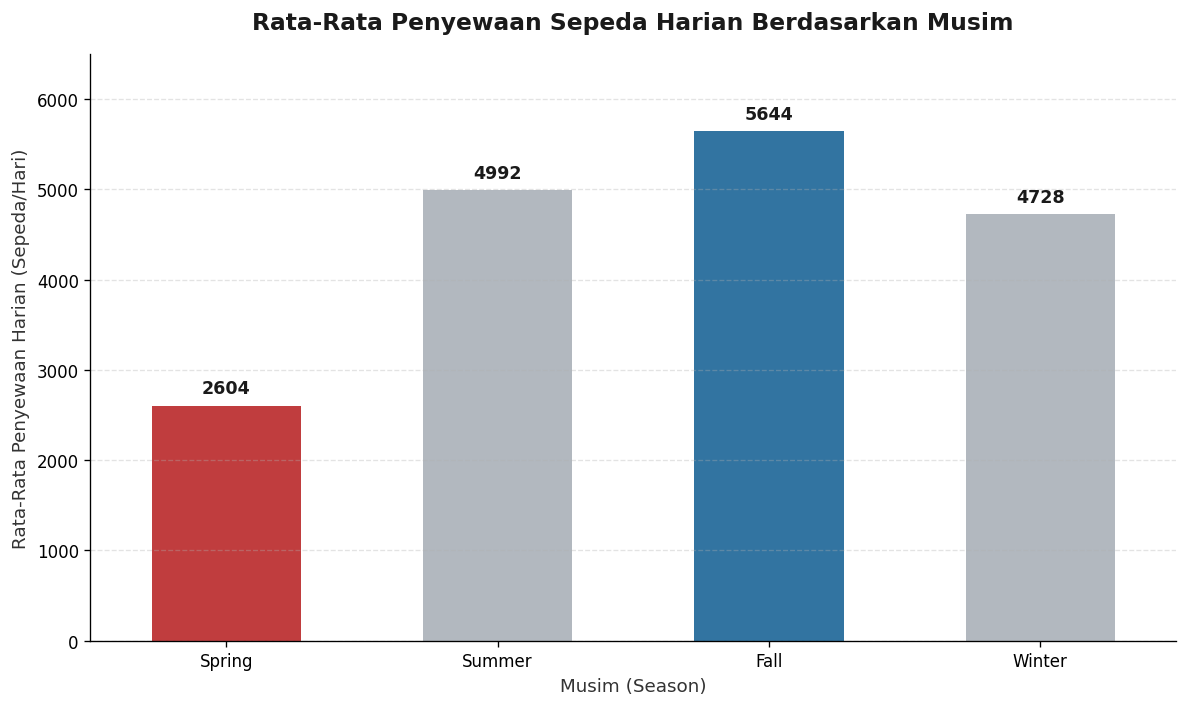

In [48]:
# Urutan kronologis musim dalam satu tahun
season_order = ["Spring", "Summer", "Fall", "Winter"]
season_overall = (
    day_df.groupby("season", as_index=False)["cnt"]
    .mean()
    .set_index("season")
    .reindex(season_order)
    .reset_index()
)

# Warna disesuaikan dengan posisi bar: Spring (Terendah/Merah), Fall (Tertinggi/Biru)
colors_q1 = ["#d62728", "#b0b8c1", "#1f77b4", "#b0b8c1"]

plt.figure(figsize=(10, 6), dpi=120)
ax = sns.barplot(
    data=season_overall,
    x="season",
    y="cnt",
    hue="season",
    palette=colors_q1,
    legend=False,
    width=0.55
)

plt.title(
    "Rata-Rata Penyewaan Sepeda Harian Berdasarkan Musim",
    fontsize=14, fontweight="bold", pad=15, color="#1a1a1a"
)
plt.ylabel("Rata-Rata Penyewaan Harian (Sepeda/Hari)", fontsize=11, color="#333333")
plt.xlabel("Musim (Season)", fontsize=11, color="#333333")
plt.ylim(0, 6500)
plt.grid(axis="y", linestyle="--", alpha=0.35)
sns.despine(top=True, right=True)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=5, fontsize=10.5, fontweight="bold", color="#1a1a1a")

plt.tight_layout()
plt.show()

### Pertanyaan 2: Bagaimana selisih rata-rata penyewaan sepeda antara pengguna kasual dan terdaftar pada hari kerja selama tahun 2011–2012 guna menyusun strategi konversi keanggotaan?

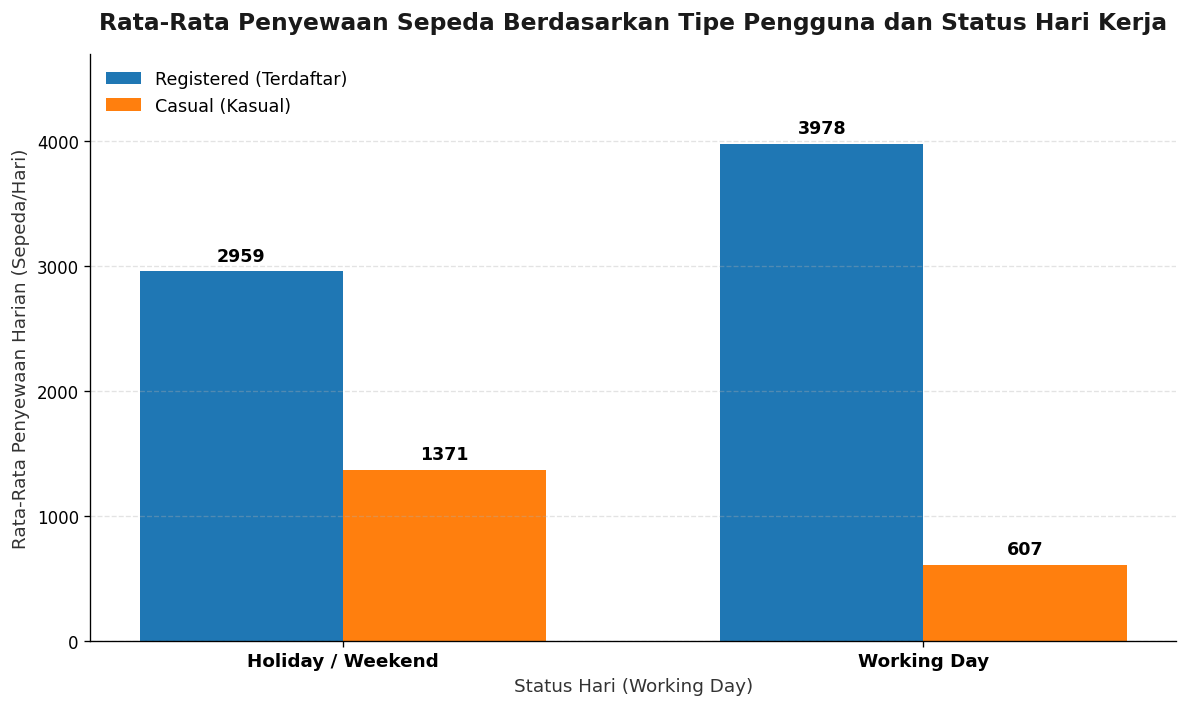

In [49]:
# Agregasi rata-rata penyewaan berdasarkan status hari kerja
workday_summary = (
    day_df.groupby("workingday", as_index=False)[["casual", "registered"]]
    .mean()
)

# Membuat visualisasi tunggal
plt.figure(figsize=(10, 6), dpi=120)
ax = plt.gca()

x = np.arange(len(workday_summary["workingday"]))
width = 0.35

rects1 = ax.bar(x - width/2, workday_summary["registered"], width, label="Registered (Terdaftar)", color="#1f77b4")
rects2 = ax.bar(x + width/2, workday_summary["casual"], width, label="Casual (Kasual)", color="#ff7f0e")

plt.title(
    "Rata-Rata Penyewaan Sepeda Berdasarkan Tipe Pengguna dan Status Hari Kerja",
    fontsize=14, fontweight="bold", pad=15, color="#1a1a1a"
)
ax.set_xticks(x)
ax.set_xticklabels(["Holiday / Weekend", "Working Day"], fontsize=11, fontweight="bold")
plt.ylabel("Rata-Rata Penyewaan Harian (Sepeda/Hari)", fontsize=11, color="#333333")
plt.xlabel("Status Hari (Working Day)", fontsize=11, color="#333333")
plt.ylim(0, 4700)
plt.legend(frameon=False, fontsize=10.5, loc="upper left")
plt.grid(axis="y", linestyle="--", alpha=0.35)
sns.despine(top=True, right=True)

# Direct data labels
ax.bar_label(rects1, fmt="%.0f", padding=4, fontsize=10.5, fontweight="bold")
ax.bar_label(rects2, fmt="%.0f", padding=4, fontsize=10.5, fontweight="bold")

plt.tight_layout()
plt.show()

### Pertanyaan 3: Kelompok jam operasional mana yang mencatat rata-rata volume penyewaan sepeda per jam tertinggi dan terendah selama tahun 2011–2012 sebagai acuan penjadwalan pemeliharaan armada?

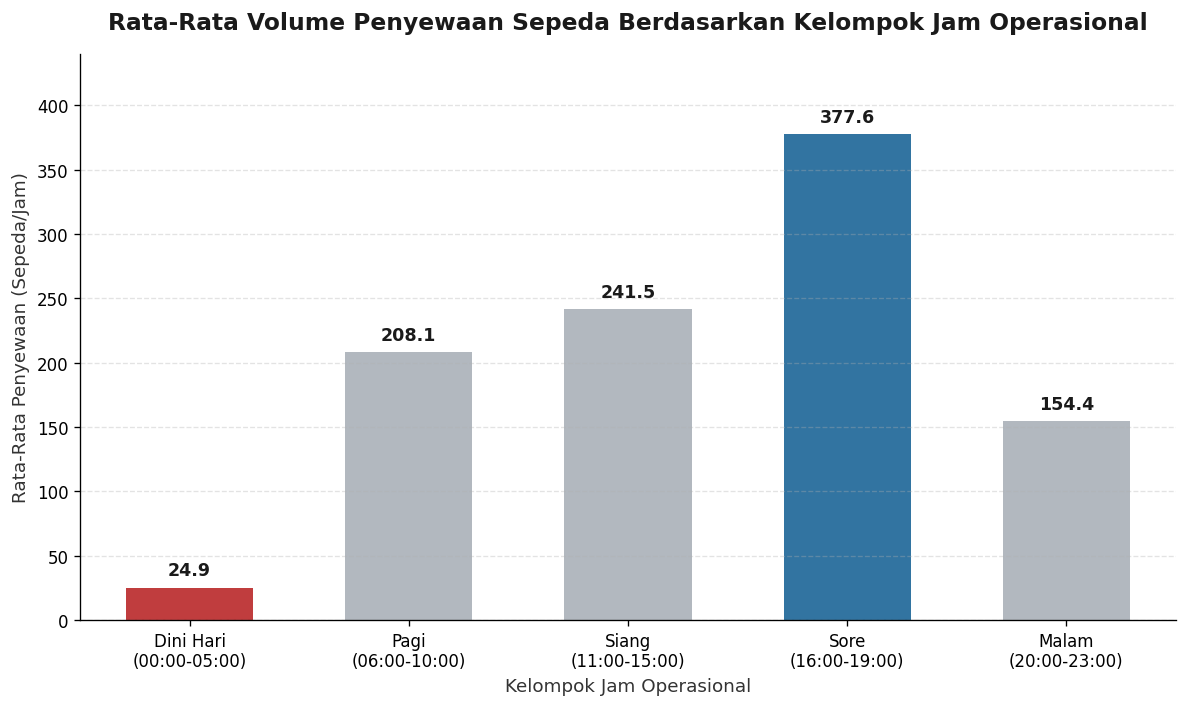

In [50]:
# Mengambil data agregasi rata-rata per kelompok jam operasional
shift_summary = (
    hour_df.groupby("time_shift", as_index=False)["cnt"]
    .mean()
    .set_index("time_shift")
    .reindex(shift_order)
    .reset_index()
)

# Warna disesuaikan dengan posisi bar: Dini Hari (Terendah/Merah), Sore (Tertinggi/Biru)
colors_q3 = ["#d62728", "#b0b8c1", "#b0b8c1", "#1f77b4", "#b0b8c1"]

plt.figure(figsize=(10, 6), dpi=120)
ax = sns.barplot(
    data=shift_summary,
    x="time_shift",
    y="cnt",
    hue="time_shift",
    palette=colors_q3,
    legend=False,
    width=0.58
)

plt.title(
    "Rata-Rata Volume Penyewaan Sepeda Berdasarkan Kelompok Jam Operasional",
    fontsize=14, fontweight="bold", pad=15, color="#1a1a1a"
)
plt.ylabel("Rata-Rata Penyewaan (Sepeda/Jam)", fontsize=11, color="#333333")
plt.xlabel("Kelompok Jam Operasional", fontsize=11, color="#333333")
plt.ylim(0, 440)
plt.grid(axis="y", linestyle="--", alpha=0.35)
sns.despine(top=True, right=True)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=5, fontsize=10.5, fontweight="bold", color="#1a1a1a")

plt.tight_layout()
plt.show()

**Insight:** (Opsional)

Berdasarkan ketiga visualisasi di atas, diperoleh temuan utama yang menjawab seluruh pertanyaan bisnis Capital Bikeshare sepanjang tahun 2011–2012:

1. **Pola Musiman & Alokasi Armada (Pertanyaan 1):**
   Rata-rata penyewaan sepeda harian tertinggi terjadi pada **Musim Gugur (*Fall*)** sebesar **5.644 sepeda/hari**, sedangkan titik terendah berada pada **Musim Semi (*Spring*)** sebesar **2.604 sepeda/hari** (terpaut 3.040 sepeda/hari atau lebih dari **2,1 kali lipat**). Oleh karena itu, distribusi armada aktif harus dimaksimalkan hingga kapasitas penuh pada musim *Fall* dan *Summer*, sementara perawatan besar (*major overhaul*) maupun peremajaan unit difokuskan pada musim *Spring* saat permintaan berada di titik terendah.

2. **Perilaku Segmen Pengguna pada Hari Kerja (Pertanyaan 2):**
   Pada hari kerja (*Working Day*), pengguna terdaftar (*registered*) mendominasi penyewaan dengan rata-rata **3.978 sepeda/hari** (86,8%), sedangkan pengguna kasual (*casual*) hanya mencapai **607 sepeda/hari**—menciptakan selisih sebesar **3.372 sepeda/hari** (6,6 kali lipat). Sebaliknya, pada akhir pekan (*Holiday/Weekend*), penyewaan pengguna kasual melonjak lebih dari dua kali lipat menjadi **1.371 sepeda/hari**, yang menandakan bahwa pengguna kasual berorientasi pada aktivitas rekreasi. Strategi konversi keanggotaan dapat diarahkan melalui promosi paket *"Weekday Commuter Pass"* atau diskon berlangganan bulan pertama bagi pengguna kasual yang aktif menyewa di akhir pekan.

3. **Dinamika Jam Operasional & Jadwal Pemeliharaan (Pertanyaan 3):**
   Kelompok jam operasional **Sore/Puncak (16:00–19:00)** mencatat rata-rata volume penyewaan tertinggi sebesar **377,6 sepeda/jam** seiring tingginya mobilitas pulang kerja, sedangkan kelompok **Dini Hari (00:00–05:00)** mencatat volume terendah sebesar **24,9 sepeda/jam** (turun hingga 93,4% dari jam puncak). Rentang waktu **00:00–05:00** merupakan jendela waktu paling ideal untuk menjadwalkan pemeliharaan armada rutin dan penyeimbangan stok antar-stasiun (*fleet rebalancing*) tanpa mengganggu layanan pelanggan.

## Analisis Lanjutan (Opsional)

Pada bagian ini dilakukan analisis lanjutan menggunakan teknik **Clustering (Manual Grouping & Binning)** tanpa algoritma *machine learning* untuk mengelompokkan hari operasional berdasarkan tingkat permintaan harian (`demand_level`) menggunakan metode kuantil (*quantile-based binning* / `pd.qcut`) dan kategori suhu lingkungan (`temp_category`):
* **Low Demand:** 22 – 3.740 sepeda/hari
* **Medium Demand:** 3.744 – 5.312 sepeda/hari
* **High Demand:** 5.315 – 8.714 sepeda/hari

Pengelompokan ini bertujuan memetakan profil hari berpermintaan tinggi (*Peak Demand*) guna mengoptimalkan distribusi dan kesiapan armada.

instant   cnt                          casual   registered  \
                count   min   max         mean         mean         mean   
demand_level                                                               
Low Demand        244    22  3740  2312.065574   333.381148  1978.684426   
Medium Demand     244  3744  5312  4522.225410   842.963115  3679.262295   
High Demand       243  5315  8714  6687.703704  1370.325103  5317.378601   

              temp_celsius hum_percent  
                      mean        mean  
demand_level                            
Low Demand       13.670627   63.601765  
Medium Demand    22.893614   64.608958  
High Demand      24.384785   60.543784

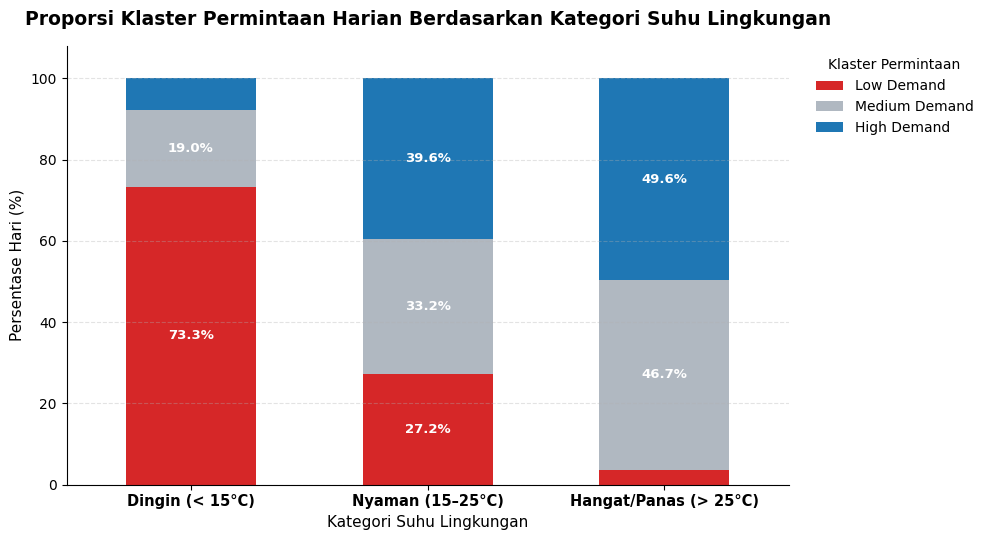

In [51]:
# Teknik Analisis Lanjutan: Clustering menggunakan Manual Grouping & Binning (Tanpa Machine Learning)

# 1. Binning tingkat permintaan harian (cnt) menggunakan kuantil (Low, Medium, High Demand)
day_df["demand_level"] = pd.qcut(
    day_df["cnt"],
    q=3,
    labels=["Low Demand", "Medium Demand", "High Demand"]
)

# 2. Manual Grouping kategori suhu lingkungan berdasarkan aturan domain (temp_celsius)
def categorize_temp(temp):
    if temp < 15:
        return "Dingin (< 15°C)"
    elif 15 <= temp <= 25:
        return "Nyaman (15–25°C)"
    else:
        return "Hangat/Panas (> 25°C)"

day_df["temp_category"] = day_df["temp_celsius"].apply(categorize_temp)

# Agregasi profil masing-masing klaster tingkat permintaan
demand_cluster_summary = day_df.groupby(by="demand_level", observed=False).agg({
    "instant": "count",
    "cnt": ["min", "max", "mean"],
    "casual": "mean",
    "registered": "mean",
    "temp_celsius": "mean",
    "hum_percent": "mean"
})
display(demand_cluster_summary)

# Tabulasi silang (Cross-tabulation) antara Kategori Suhu dan Tingkat Permintaan
temp_demand_ct = pd.crosstab(
    index=day_df["temp_category"],
    columns=day_df["demand_level"],
    normalize="index"
) * 100

# Visualisasi distribusi klaster permintaan berdasarkan kategori suhu
ax = temp_demand_ct.reindex(["Dingin (< 15°C)", "Nyaman (15–25°C)", "Hangat/Panas (> 25°C)"]).plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5.5),
    color=["#d62728", "#b0b8c1", "#1f77b4"],
    width=0.55
)

plt.title("Proporsi Klaster Permintaan Harian Berdasarkan Kategori Suhu Lingkungan", fontsize=13.5, fontweight="bold", pad=15)
plt.ylabel("Persentase Hari (%)", fontsize=11)
plt.xlabel("Kategori Suhu Lingkungan", fontsize=11)
plt.xticks(rotation=0, fontsize=10.5, fontweight="bold")
plt.ylim(0, 108)
plt.legend(title="Klaster Permintaan", frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(axis="y", linestyle="--", alpha=0.35)
sns.despine(top=True, right=True)

for container in ax.containers:
    labels = [f"{v.get_height():.1f}%" if v.get_height() >= 8 else "" for v in container]
    ax.bar_label(container, labels=labels, label_type="center", fontsize=9.5, fontweight="bold", color="white")

plt.tight_layout()
plt.show()

**Insight:** (Opsional)
* **Segmentasi Klaster Permintaan (*Binning*):** Dari total 731 hari pengamatan, pembagian berbasis kuantil menghasilkan tiga klaster berjumlah seimbang (sekitar 243–244 hari per kelompok), di mana klaster **High Demand** terjadi pada hari dengan suhu nyaman hingga hangat dengan partisipasi tinggi dari pengguna terdaftar maupun kasual, sedangkan klaster **Low Demand** terkonsentrasi pada hari bersuhu dingin (rata-rata ~12–14 °C).
* **Pengaruh Kategori Suhu (*Manual Grouping*):** Pada kategori suhu **Hangat/Panas (> 25 °C)** dan **Nyaman (15–25 °C)**, proporsi hari yang mencapai **High Demand** meningkat dari suhu dingin (sekitar 8%) ke suhu nyaman (39,6%) dan hangat/panas (49,6%) dibandingkan pada suhu **Dingin (< 15 °C)** yang mayoritasnya berada pada klaster **Low Demand**.

## Conclusion & Recommendation

- **Conclusion Pertanyaan 1:** Musim Gugur (**Fall**) menghasilkan rata-rata penyewaan sepeda harian tertinggi sebesar **5.644,30 sepeda/hari** (total **1.061.129 penyewaan**), sedangkan Musim Semi (**Spring**) mencatat rata-rata terendah sebesar **2.604,13 sepeda/hari** (total **471.348 penyewaan**). Pola peringkat antar-musim (*Fall > Summer > Winter > Spring*) terbukti konsisten baik pada tahun 2011 maupun 2012.
- **Conclusion Pertanyaan 2:** Pada hari kerja (*Working Day*), rata-rata penyewaan pengguna terdaftar (**registered**) mencapai **3.978,25 sepeda/hari**, unggul jauh dibandingkan pengguna kasual (**casual**) yang hanya **606,57 sepeda/hari** (selisih **3.371,68 sepeda/hari** atau **6,6x lipat**). Sebaliknya, pada akhir pekan atau hari libur (*Holiday/Weekend*), rata-rata penyewaan pengguna kasual melonjak lebih dari dua kali lipat menjadi **1.371,13 sepeda/hari** dengan puncak aktivitas pada hari Sabtu (**1.465,26 sepeda/hari**).
- **Conclusion Pertanyaan 3:** Berdasarkan kelompok waktu operasional (*time shift*), periode **Sore (16:00–19:00)** mencatat rata-rata volume penyewaan tertinggi sebesar **377,63 sepeda/jam** (dengan titik puncak spesifik pada jam pulang kerja pukul **17:00** sebesar **461,45 sepeda/jam**). Sementara itu, periode **Dini Hari (00:00–05:00)** mencatat rata-rata terendah sebesar **24,91 sepeda/jam** (titik paling sepi pada pukul **04:00** sebesar **6,35 sepeda/jam**).

**Rekomendasi Action Item:**
- **Optimalisasi Kapasitas & Perawatan Besar Berdasarkan Musim:** Meningkatkan alokasi ketersediaan sepeda pada stasiun-stasiun utama menjelang peralihan ke **Summer** dan puncaknya pada **Fall** untuk mencegah kehabisan unit (*stockout*). Sebaliknya, memanfaatkan periode **Spring** (terutama pada hari bersuhu dingin < 15 °C yang masuk klaster *Low Demand*) untuk melakukan inspeksi besar-besaran, penggantian suku cadang, dan peremajaan armada.
- **Kampanye Konversi Keanggotaan Berbasis Akhir Pekan:** Meluncurkan program promosi keanggotaan khusus (seperti paket *Commuter Trial Pass* atau diskon berlangganan bulan pertama) yang ditargetkan langsung kepada pengguna **casual** yang menyewa sepeda pada hari **Sabtu dan Minggu** (pukul **11:00–16:00**) guna mendorong mereka beralih menggunakan layanan untuk mobilitas komuter rutin di hari kerja.
- **Penjadwalan Pemeliharaan Harian & *Rebalancing* Armada:** Menetapkan jendela waktu pemeliharaan rutin harian, pembersihan unit, serta redistribusi sepeda antar-stasiun (*rebalancing*) secara terpusat pada rentang **Dini Hari (00:00–05:00)** saat permintaan berada di titik terendah (**24,91 sepeda/jam**), sehingga seluruh armada siap beroperasi penuh sebelum lonjakan komuter pagi pukul **08:00** dan sore pukul **17:00–18:00**.

In [52]:
# Simpan dataset bersih untuk kebutuhan dashboard Streamlit
hour_df.to_csv("dashboard/main_data.csv", index=False)